# Hyperparameter Optimization with Bayesian Search Cross-Validation

In this notebook, we examine train several models, examine their performance, and create visualizations for these models related to explanations and their performance.
- Train models (XGBoost, Random Forest, and Linear Regression)
- Examine test performance of each model using density scatter plots with RMSE/$R^2$/MBE information for all models
- Use trained model to examine SHAP values on the test set for each model across datasets (bar plot and beeswarm plot)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats

from sklearnex import patch_sklearn
patch_sklearn()

import os
os.environ["SKLEARNEX_VERBOSE"] = "INFO"

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
import statsmodels.api as sm
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from skopt import BayesSearchCV
from skopt.space import Real, Integer, Categorical
import joblib
import mpl_scatter_density
from matplotlib.colors import LinearSegmentedColormap
import shap

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

Intel(R) Extension for Scikit-learn* enabled (https://github.com/intel/scikit-learn-intelex)


## Data

In [2]:
# Mapping dictionary
mapping_dict = {'Arid': 0, 'Snow': 1, 'Temperate': 2, 'Tropical': 3}

In [3]:
old_cols = ['BSA', 'NDBI', 'NDVI', 'DEM']
new_cols = ['\u0394BSA', '\u0394NDBI', '\u0394NDVI', '\u0394DEM']

In [4]:
# NTL dataset
data_ntl                 = pd.read_csv('data/data_ntl.csv')
data_ntl['Coastal?']     = data_ntl['Coastal?'].astype(int)
data_ntl['Climate Zone'] = data_ntl['Climate Zone'].map(mapping_dict)
data_ntl.rename(columns=dict(zip(old_cols, new_cols)), inplace=True)

In [5]:
# SUE dataset
data_sue                 = pd.read_csv('data/data_sue.csv')
data_sue['Coastal?']     = data_sue['Coastal?'].fillna(False).astype(int)
data_sue['Climate Zone'] = data_sue['Climate Zone'].map(mapping_dict)
data_sue.rename(columns=dict(zip(old_cols, new_cols)), inplace=True)

In [6]:
features = ['\u0394BSA', '\u0394NDBI', '\u0394NDVI', '\u0394DEM', 'Coastal?', 'Climate Zone']
label    = 'SUHI'

## Helper Functions

In [7]:
def get_data(df, test_size=0.20):
    df = df[features+[label]].dropna().copy()
    X  = df[features]
    y  = df[label]
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size,  random_state=1, shuffle=True)
    return X_train, X_test, y_train, y_test

In [8]:
def get_linear_model(df):
    df = df[features+[label]].dropna().copy()
    X  = df[features]
    X  = sm.add_constant(X)
    y  = df[label]
    
    model   = sm.OLS(y, np.asarray(X))
    results = model.fit()
    return results

- [Density Scatter Plot Code](https://stackoverflow.com/questions/20105364/how-can-i-make-a-scatter-plot-colored-by-density)
- [Density Scatter Plot Library](https://github.com/astrofrog/mpl-scatter-density/tree/main)

In [9]:
# Test Performance Graphs
def performance_graphs(model_xgb, model_rf, X_test, y_test, dataset, filename):
    model_linear = get_linear_model(dataset)
    
    models = [model_rf, model_xgb, model_linear]
    if filename == 'SUE':
        titles = ['1(a) Random Forest - SUE', '1(b) XGBoost - SUE', '1(c) OLS - SUE']
    if filename == 'NTL':
        titles = ['2(a) Random Forest - NTL', '2(b) XGBoost - NTL', '2(c) OLS - NTL']
    
    # "Viridis-like" colormap with white background
    white_viridis = LinearSegmentedColormap.from_list('white_viridis', [
        (0, '#ffffff'),
        (1e-20, '#440053'),
        (0.2, '#404388'),
        (0.4, '#2a788e'),
        (0.6, '#21a784'),
        (0.8, '#78d151'),
        (1, '#fde624'),
    ], N=256)

    font = {'size': 14}
    plt.rc('font', **font)
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["font.sans-serif"] = ["Verdana"]
    nrows, ncols = 1, len(models)
    fig = plt.figure(figsize=(15,5), constrained_layout=True, dpi=1000)
    lim = [-15,15]
    dpi = 30
    for i in range(len(models)-1):
        y_pred = models[i].predict(X_test)
        rmse = mean_squared_error(y_test, y_pred, squared = False)
        r2   = r2_score(y_test, y_pred)
        mbe  = np.mean(y_pred - y_test)
        # Scatter Density Plot
        ax = fig.add_subplot(nrows, ncols, i+1, projection='scatter_density')
        density = ax.scatter_density(y_pred, y_test, cmap=white_viridis, dpi=dpi)
        ax.set_xlabel('Predicted SUHI', fontsize=16)
        if i == 0:
            ax.set_ylabel('Observed SUHI', fontsize=16)
        ax.set_title(titles[i], fontsize=18)
        # Line of Best Fit
        slope, intercept, r_value, p_value, std_err = stats.linregress(y_pred, y_test)
        y_test_scipy = slope * y_pred + intercept
        operator = "+" if intercept >= 0 else ""
        if round(abs(mbe), 2) == 0:
            perf_label = f"y = {slope:.2f}x{operator}${intercept:.2f}$; $R^2$={r_value ** 2:.2f}\nRMSE={rmse:.2f}\u00b0C; MBE$\\approx$0\u00b0C"
            if round(abs(intercept), 2) == 0:
                perf_label = f"y = {slope:.2f}x; $R^2$={r_value ** 2:.2f}\nRMSE={rmse:.2f}\u00b0C; MBE$\\approx$0\u00b0C"
        else:
            perf_label = f"y = {slope:.2f}x{operator}${intercept:.2f}$; $R^2$={r_value ** 2:.2f}\nRMSE={rmse:.2f}\u00b0C; MBE=${mbe:.2f}$\u00b0C"
            if round(abs(intercept), 2) == 0:
                perf_label = f"y = {slope:.2f}x; $R^2$={r_value ** 2:.2f}\nRMSE={rmse:.2f}\u00b0C; MBE=${mbe:.2f}$\u00b0C"
        ax.plot(y_pred, y_test_scipy, color='black', linestyle='solid', label=perf_label)
        ax.legend(loc='lower right')
        # Perfect Performance Line
        ax.plot(y_test, y_test, linestyle='dashed', color='red')
        ax.set_xlim(lim)
        ax.set_ylim(lim)
        ax.tick_params(axis='both', which='major', labelsize=14)

    y_pred = model_linear.predict(sm.add_constant(X_test))
    rmse = mean_squared_error(y_test, y_pred, squared = False)
    r2   = r2_score(y_test, y_pred)
    mbe  = np.mean(y_pred - y_test)
    ax = fig.add_subplot(nrows, ncols, len(models), projection='scatter_density')
    density = ax.scatter_density(y_pred, y_test, cmap=white_viridis, dpi=dpi)
    #fig.colorbar(density, label='Number of points per pixel')
    ax.set_xlabel('Predicted SUHI', fontsize=16)
    ax.set_title(titles[-1], fontsize=18)
    # Line of Best Fit
    slope, intercept, r_value, p_value, std_err = stats.linregress(y_pred, y_test)
    y_test_scipy = slope * y_pred + intercept
    operator = "+" if intercept >= 0 else ""
    if round(abs(mbe), 2) == 0:
        perf_label = f"y = {slope:.2f}x{operator}${intercept:.2f}$; $R^2$={r_value ** 2:.2f}\nRMSE={rmse:.2f}\u00b0C; MBE$\\approx$0\u00b0C"
        if round(abs(intercept), 2) == 0:
                perf_label = f"y = {slope:.2f}x; $R^2$={r_value ** 2:.2f}\nRMSE={rmse:.2f}\u00b0C; MBE$\\approx$0\u00b0C"
    else:
        perf_label = f"y = {slope:.2f}x{operator}${intercept:.2f}$; $R^2$={r_value ** 2:.2f}\nRMSE={rmse:.2f}\u00b0C; MBE=${mbe:.2f}$\u00b0C"
        if round(abs(intercept), 2) == 0:
                perf_label = f"y = {slope:.2f}x; $R^2$={r_value ** 2:.2f}\nRMSE={rmse:.2f}\u00b0C; MBE=${mbe:.2f}$\u00b0C"
    ax.plot(y_pred, y_test_scipy, color='black', linestyle='solid', label=perf_label)
    ax.legend(loc='lower right')
    # Perfect Performance Line
    ax.plot(y_test, y_test, linestyle='dashed', color='red')
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    plt.savefig('graphs/performance/{}.svg'.format(filename), bbox_inches='tight', dpi=1000)

In [10]:
# Save SHAP values for test set
def explain_model(model_xgb, model_rf, X_test, y_test, filename):
    models = [model_xgb, model_rf]
    model_names = ['xgb', 'rf']
    
    if filename == 'SUE':
        titles = ['1(a) Feature Importance - SUE', '1(b) Feature Effect - SUE']
    if filename == 'NTL':
        titles = ['2(a) Feature Importance - NTL', '2(b) Feature Effect - NTL']
    
    for i in range(len(models)):
        # Compute SHAP values for test set
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,5), dpi=1000)
        # SHAP
        explainer = shap.TreeExplainer(models[i], approximate=True)
        shap_values = explainer(X_test)
        # Create a SHAP bar and beeswarm plot
        plt.sca(ax1)
        shap.plots.bar(shap_values, max_display=10, show=False)
        ax1.set_title(titles[0])
        plt.sca(ax2)
        shap.plots.beeswarm(shap_values, max_display=10, show=False)
        ax2.tick_params(axis='y', which='both', left=False, labelleft=False)
        ax2.set_xlabel('SHAP value')
        ax2.set_title(titles[1])
        plt.subplots_adjust(
            wspace = 0.1)
        fig.set_size_inches(10, 5)
        font = {'size': 14}
        plt.rc('font', **font)
        plt.rcParams["font.family"] = "sans-serif"
        plt.rcParams["font.sans-serif"] = ["Verdana"]

        plt.savefig('graphs/shap/feature_importance_{}_{}.svg'.format(model_names[i], filename), bbox_inches='tight', dpi=1000)

In [11]:
def shap_pdp(model_xgb, model_rf, X_test, y_test, filename):
    models = [model_xgb, model_rf]
    model_names = ['xgb', 'rf']
    
    for i in range(len(models)):
        for j in range(4):
            shap.plots.partial_dependence(features[j], 
                                          models[i].predict, 
                                          X_test[features], 
                                          model_expected_value=True, 
                                          feature_expected_value=True, 
                                          ice=False, 
                                          show=False)
            font = {'size': 16}
            plt.rc('font', **font)
            plt.rcParams["font.family"] = "sans-serif"
            plt.rcParams["font.sans-serif"] = ["Verdana"]
            plt.savefig('graphs/pdp/pdp_{}_{}_{}.svg'.format(features[j], model_names[i], filename), bbox_inches='tight', dpi=1000)
            

In [12]:
def shap_interact(model_xgb, model_rf, X_test, y_test, filename):
    models = [model_xgb, model_rf]
    model_names = ['xgb', 'rf']
    biophysical = ['\u0394NDBI', '\u0394DEM', '\u0394BSA', 'Climate Zone']
    ndvi = '\u0394NDVI'
    cz_xlabels = ['Arid', 'Snow', 'Temperate', 'Tropical']   
    if filename == 'SUE':
        refs = ['1(a)', '1(b)', '1(c)', '1(d)']
    if filename == 'NTL':
        refs = ['2(a)', '2(b)', '2(c)', '2(d)']
    for i in range(len(models)):
        # Rest versus NDVI
        fig, axes = plt.subplots(nrows=1, ncols=4, figsize=(20,5), constrained_layout=True)
        for k, ax in enumerate(axes.flatten()):
            explainer = shap.TreeExplainer(models[i], approximate=True)
            shap_values = explainer(X_test)
            shap.plots.scatter(shap_values[:, biophysical[k]], color=shap_values[:, ndvi], show=False, ax=ax)
            ax.text(0.01, 0.99, refs[k],
                    transform=ax.transAxes,  # Use axes coordinates (0-1)
                    horizontalalignment='left',  # Align text to the left of the point
                    verticalalignment='top',      # Align text to the top of the point
                    fontsize=16)
        axes[3].set_xticks([0,1,2,3])
        axes[3].set_xticklabels(cz_xlabels)
        font = {'size': 16}
        plt.rc('font', **font)
        plt.rcParams["font.family"] = "sans-serif"
        plt.rcParams["font.sans-serif"] = ["Verdana"]
        plt.savefig('graphs/shap_interaction/shap_interaction_biophsyical1_{}_{}.svg'.format(model_names[i], filename), bbox_inches='tight', dpi=1000)
        
        # NDVI versus rest
        fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15,5), constrained_layout=True)
        for k, ax in enumerate(axes.flatten()):
            explainer = shap.TreeExplainer(models[i], approximate=True)
            shap_values = explainer(X_test)
            shap.plots.scatter(shap_values[:, ndvi], color=shap_values[:, biophysical[k]], show=False, ax=ax)
            ax.text(0.95, 0.99, refs[k],
                    transform=ax.transAxes,  # Use axes coordinates (0-1)
                    horizontalalignment='right',  # Align text to the left of the point
                    verticalalignment='top',      # Align text to the top of the point
                    fontsize=16)
        #axes[3].set_xticks([0,1,2,3])
        #axes[3].set_xticklabels(cz_xlabels)
        font = {'size': 16}
        plt.rc('font', **font)
        plt.rcParams["font.family"] = "sans-serif"
        plt.rcParams["font.sans-serif"] = ["Verdana"]
        plt.savefig('graphs/shap_interaction/shap_interaction_biophsyical2_{}_{}.svg'.format(model_names[i], filename), bbox_inches='tight', dpi=1000)


In [13]:
def run_search(dataset, filename, n_folds=10, n_iter = 20):
    X_train, X_test, y_train, y_test = get_data(dataset)
    
    # Define search space
    search_space = {
        'max_depth': Integer(5, 15), #Integer(5, 7), 
        'n_estimators': Integer(10, 150) #Integer(10, 20)
    }
    
    # Create model
    model_rf = RandomForestRegressor(random_state=1)

    # Perform Bayesian optimization with cross validation
    print('Random Forest')
    bayes_search_rf = BayesSearchCV(estimator=model_rf, search_spaces=search_space, n_iter=n_iter, cv=n_folds, n_jobs=-1, 
                                    error_score='raise', return_train_score=True, scoring = 'neg_root_mean_squared_error')
    bayes_search_rf.fit(X_train, y_train)
    
    # Print best score and parameters
    print(f"Best score RF: {bayes_search_rf.best_score_:.3f}")
    print(f"Best parameters RF: {bayes_search_rf.best_params_}")
    
    # Create model
    model_xgb = XGBRegressor(importance_type='gain', random_state=1, tree_method='hist', grow_policy = 'lossguide')

    # Perform Bayesian optimization with cross validation
    print('\nXGBoost')
    bayes_search_xgb = BayesSearchCV(estimator=model_xgb, search_spaces=search_space, n_iter=n_iter, cv=n_folds, n_jobs=-1, 
                                     error_score='raise', return_train_score=True, scoring = 'neg_root_mean_squared_error')
    bayes_search_xgb.fit(X_train, y_train)

    # Print best score and parameters
    print(f"Best score XGB: {bayes_search_xgb.best_score_:.3f}")
    print(f"Best parameters XGB: {bayes_search_xgb.best_params_}")
        
    performance_graphs(bayes_search_xgb.best_estimator_, bayes_search_rf.best_estimator_, X_test, y_test, dataset, filename)
    
    explain_model(bayes_search_xgb.best_estimator_, bayes_search_rf.best_estimator_, X_test, y_test, filename)
    shap_pdp(bayes_search_xgb.best_estimator_, bayes_search_rf.best_estimator_, X_test, y_test, filename)
    shap_interact(bayes_search_xgb.best_estimator_, bayes_search_rf.best_estimator_, X_test, y_test, filename)
    
    return bayes_search_rf.best_estimator_, bayes_search_xgb.best_estimator_, bayes_search_rf.cv_results_, bayes_search_xgb.cv_results_


In [14]:
def save_cv_results(filename, cv_results_rf, cv_results_xgb):
    pd.DataFrame(cv_results_rf).to_csv('tables/cv_results/{}_rf.csv'.format(filename),index=False)
    pd.DataFrame(cv_results_xgb).to_csv('tables/cv_results/{}_xgb.csv'.format(filename),index=False)
    return

In [15]:
def save_models(filename, best_rf, best_xgb):
    joblib.dump(best_rf, 'models/cross_val/' + filename + '_rf_estimator.joblib') 
    joblib.dump(best_xgb, 'models/cross_val/' + filename + '_xgb_estimator.joblib') 
    return

In [16]:
def run_all(dataset, filename):
    best_rf, best_xgb, cv_results_rf, cv_results_xgb = run_search(dataset, filename)
        
    save_cv_results(filename, cv_results_rf, cv_results_xgb)
    save_models(filename, best_rf, best_xgb)
    
    y_pred_rf  = best_rf.predict(dataset[features+[label]].dropna().copy()[features])
    y_pred_xgb = best_xgb.predict(dataset[features+[label]].dropna().copy()[features])
    y_full = dataset[features+[label]].dropna().copy()[label]
    
    print('Full Dataset Performance - {}'.format(filename))
    print('----------------------------')
    print('Random Forest')
    print('R2: ', round(r2_score(y_full, y_pred_rf),2))
    print('Root Mean Squared Error: ', round(mean_squared_error(y_full, y_pred_rf, squared = False),2))
    print('Mean Bias Error: ', round(np.mean(y_pred_rf - y_full),2))
    print('----------------------------')
    print('XGBoost')
    print('R2: ', round(r2_score(y_full, y_pred_xgb),2))
    print('Root Mean Squared Error: ', round(mean_squared_error(y_full, y_pred_xgb, squared = False),2))
    print('Mean Bias Error: ', round(np.mean(y_pred_xgb - y_full),2))
    return

## Models

### SUE

**TODO**
- Add sub-figure labels to SHAP Interaction Plots
- See if saving figure functionality works
- Do NDVI versus rest as well


Random Forest
Best score RF: -1.522
Best parameters RF: OrderedDict([('max_depth', 15), ('n_estimators', 150)])

XGBoost
Best score XGB: -1.517
Best parameters XGB: OrderedDict([('max_depth', 5), ('n_estimators', 150)])


All-NaN slice encountered
All-NaN slice encountered
All-NaN slice encountered
All-NaN slice encountered
All-NaN slice encountered
All-NaN slice encountered


Full Dataset Performance - SUE
----------------------------
Random Forest
R2:  0.84
Root Mean Squared Error:  1.23
Mean Bias Error:  0.0
----------------------------
XGBoost
R2:  0.8
Root Mean Squared Error:  1.36
Mean Bias Error:  -0.0


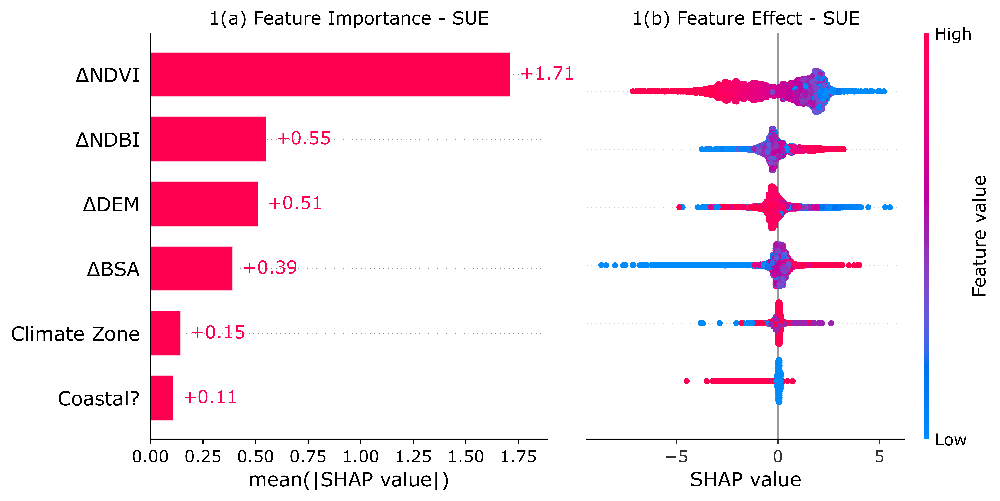

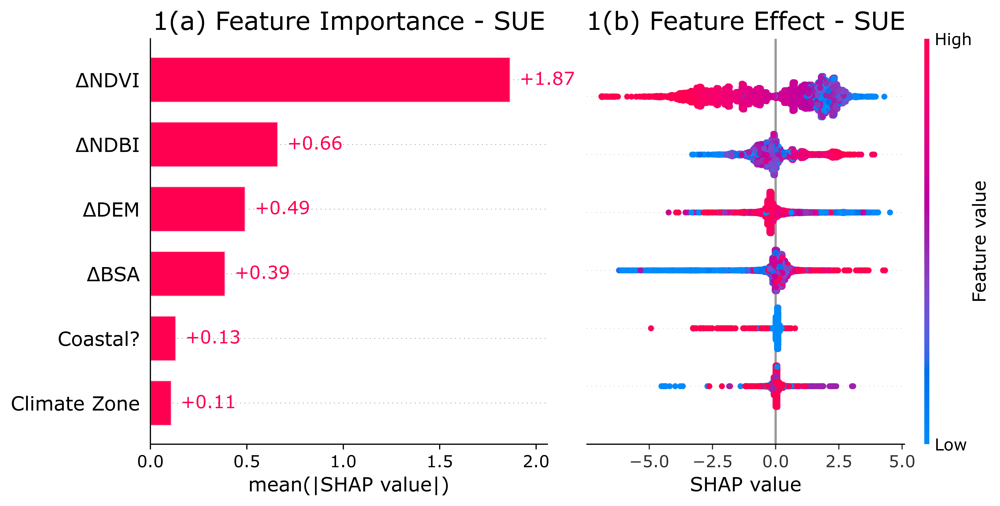

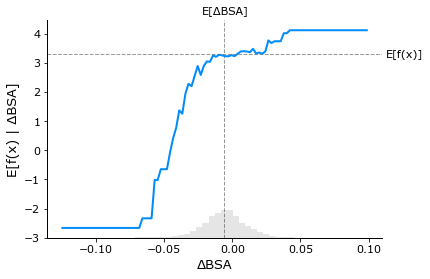

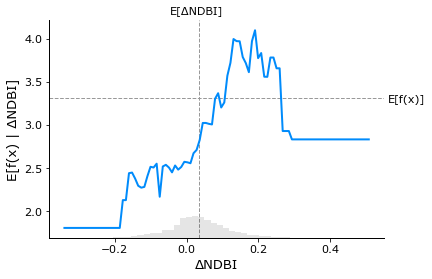

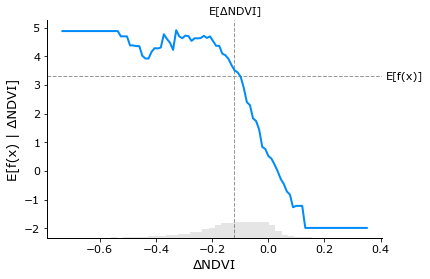

...

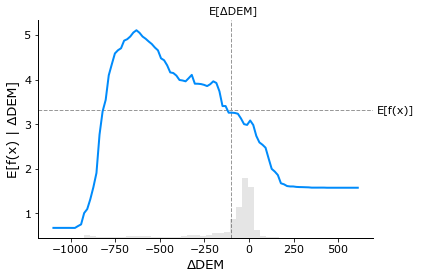

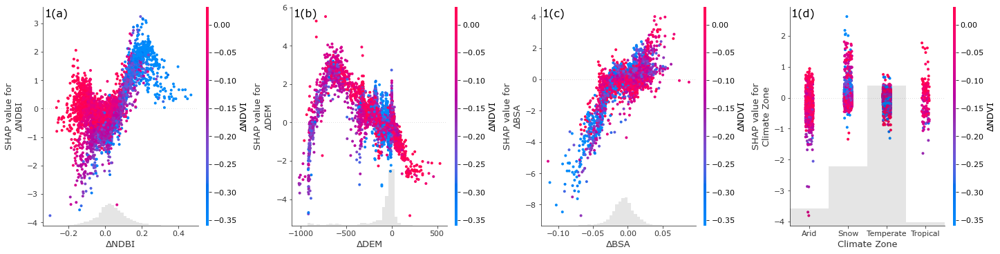

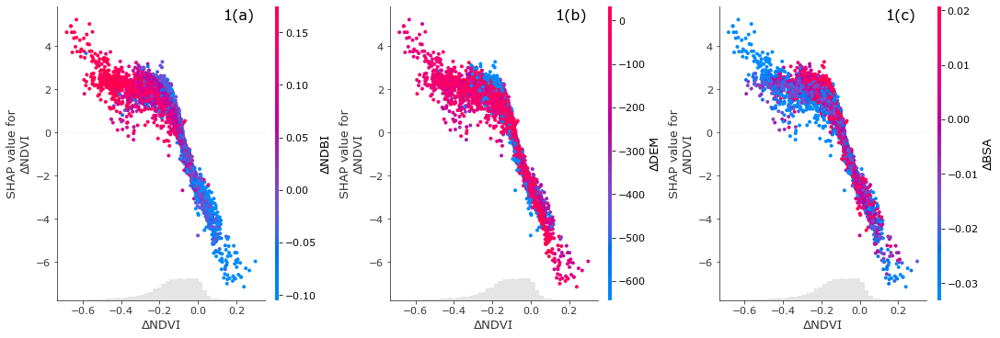

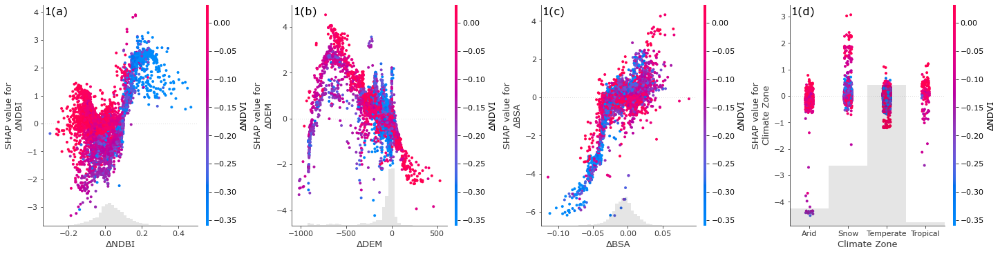

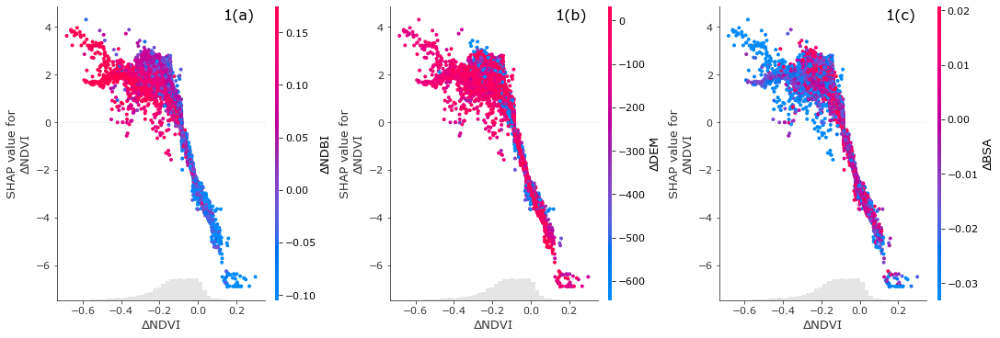

In [17]:
run_all(data_sue, 'SUE')

Random Forest


The objective has been evaluated at point [15, 150] before, using random point [8, 104]


Best score RF: -1.522
Best parameters RF: OrderedDict([('max_depth', 15), ('n_estimators', 150)])

XGBoost
Best score XGB: -1.517
Best parameters XGB: OrderedDict([('max_depth', 5), ('n_estimators', 150)])


All-NaN slice encountered
All-NaN slice encountered
All-NaN slice encountered
All-NaN slice encountered
All-NaN slice encountered
All-NaN slice encountered


Full Dataset Performance - SUE
----------------------------
Random Forest
R2:  0.84
Root Mean Squared Error:  1.23
Mean Bias Error:  0.0
----------------------------
XGBoost
R2:  0.8
Root Mean Squared Error:  1.36
Mean Bias Error:  -0.0


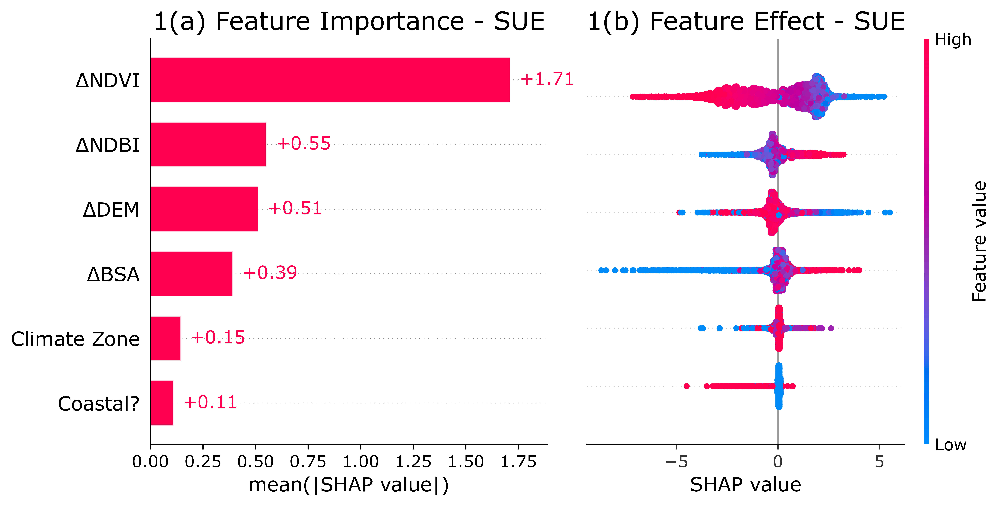

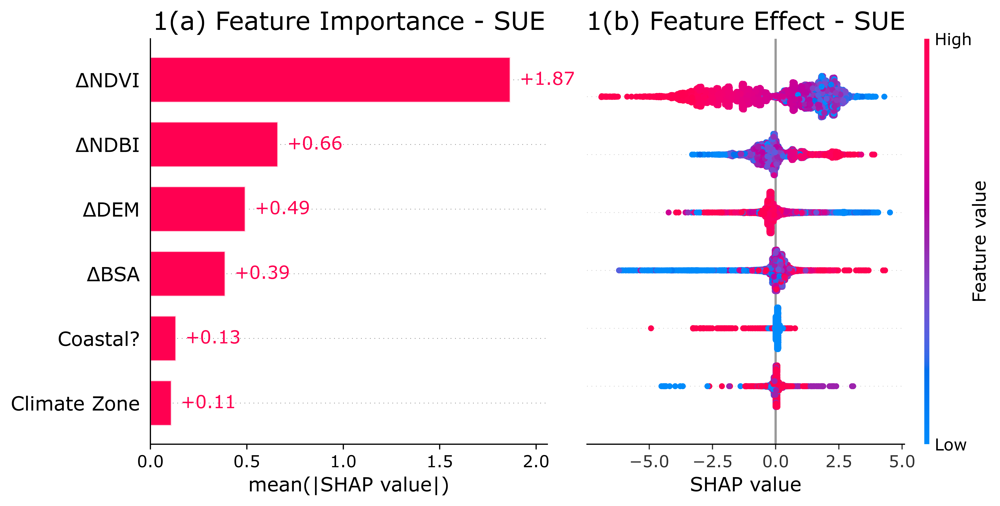

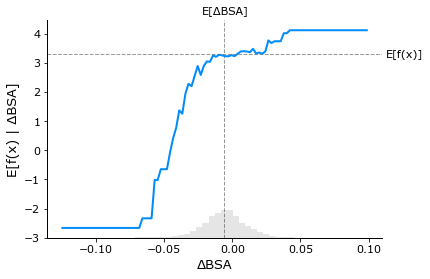

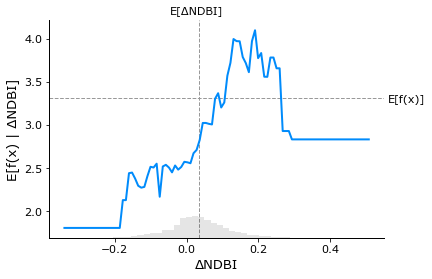

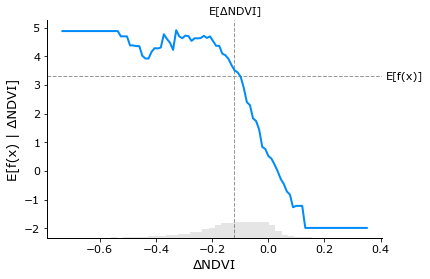

...

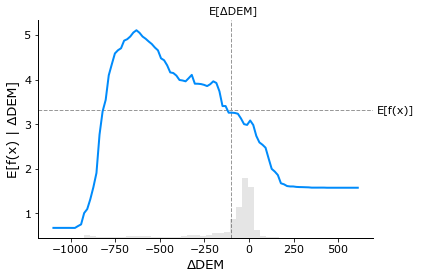

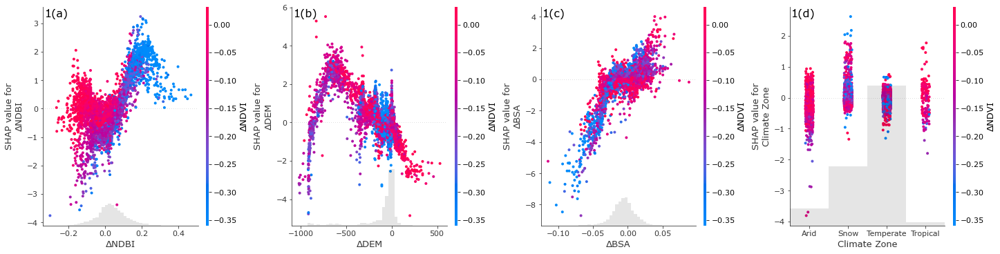

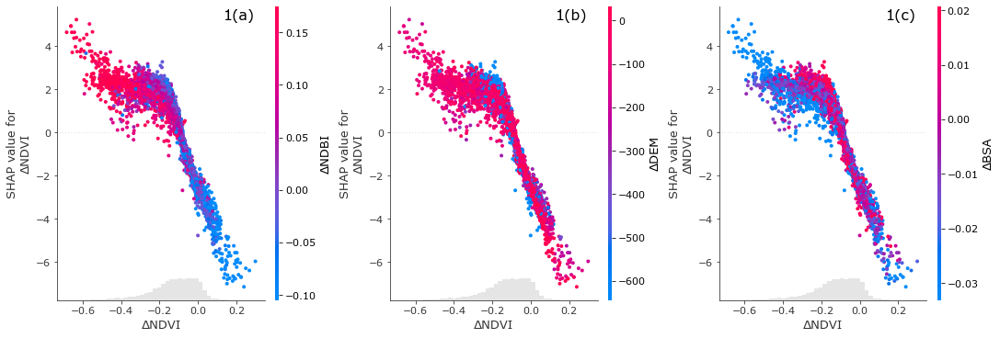

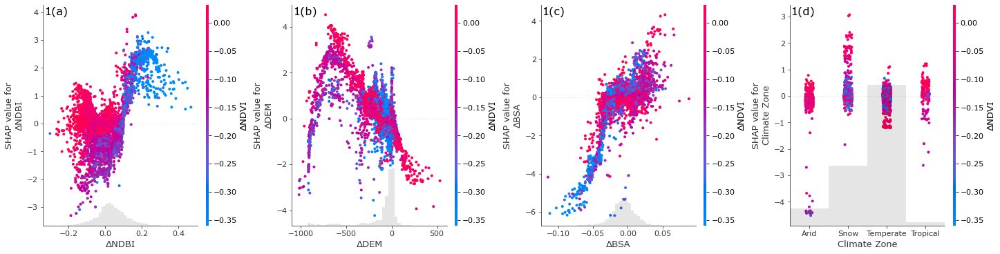

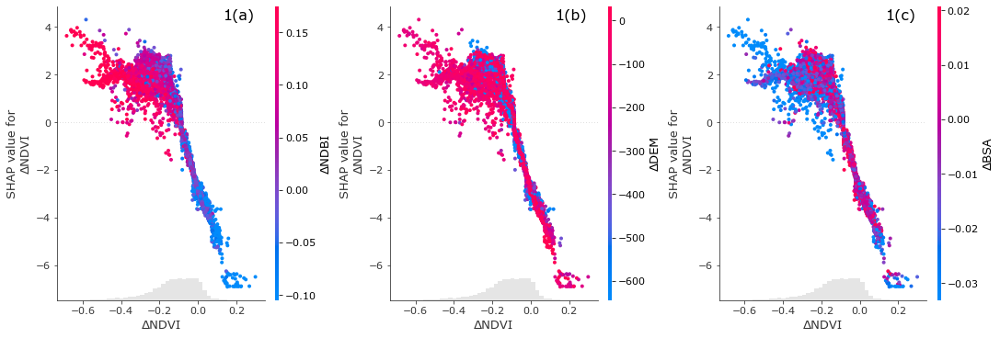

In [18]:
run_all(data_sue, 'SUE')

### NTL

Random Forest


The objective has been evaluated at point [15, 150] before, using random point [9, 137]
The objective has been evaluated at point [15, 150] before, using random point [5, 113]
The objective has been evaluated at point [15, 150] before, using random point [7, 107]
The objective has been evaluated at point [15, 150] before, using random point [8, 15]
The objective has been evaluated at point [15, 149] before, using random point [14, 141]
The objective has been evaluated at point [15, 150] before, using random point [5, 24]
The objective has been evaluated at point [15, 150] before, using random point [10, 99]


Best score RF: -1.906
Best parameters RF: OrderedDict([('max_depth', 15), ('n_estimators', 149)])

XGBoost
Best score XGB: -1.942
Best parameters XGB: OrderedDict([('max_depth', 9), ('n_estimators', 24)])


All-NaN slice encountered
All-NaN slice encountered
All-NaN slice encountered
All-NaN slice encountered
All-NaN slice encountered
All-NaN slice encountered


Full Dataset Performance - NTL
----------------------------
Random Forest
R2:  0.85
Root Mean Squared Error:  1.5
Mean Bias Error:  0.0
----------------------------
XGBoost
R2:  0.81
Root Mean Squared Error:  1.68
Mean Bias Error:  -0.0


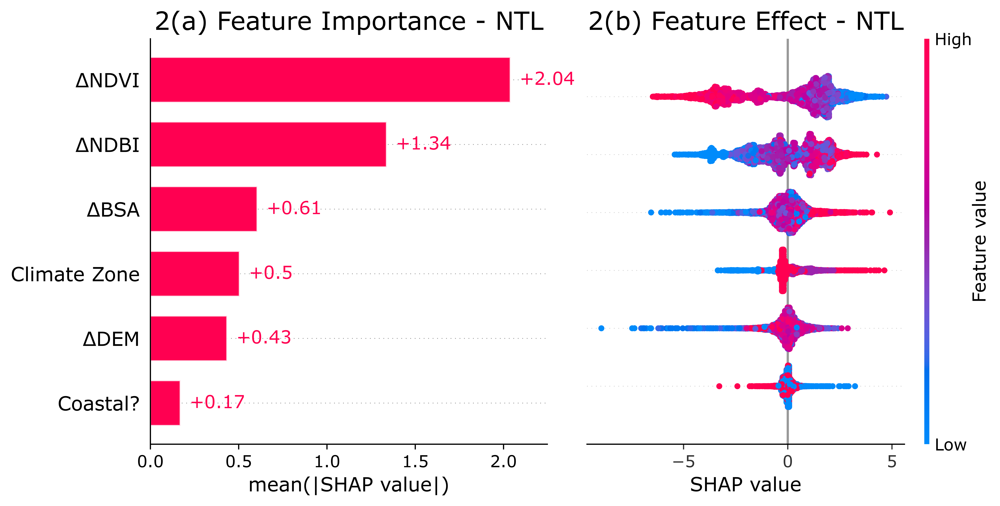

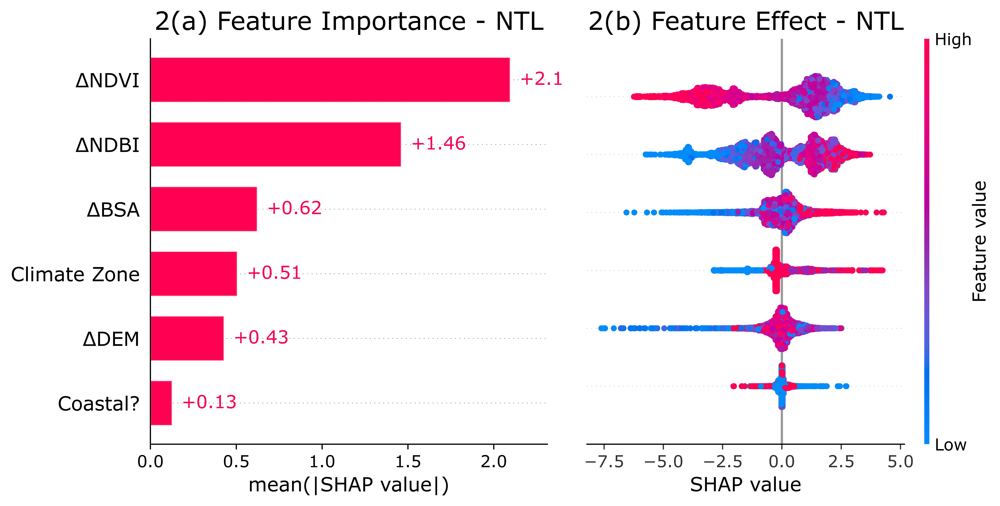

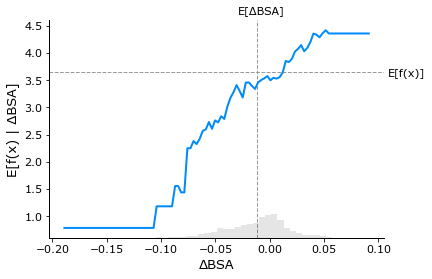

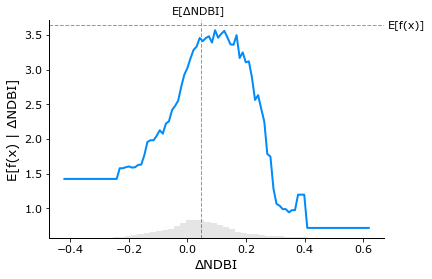

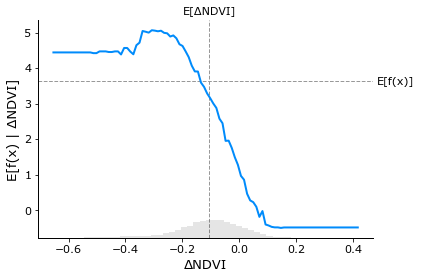

...

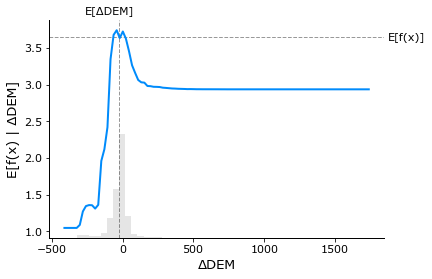

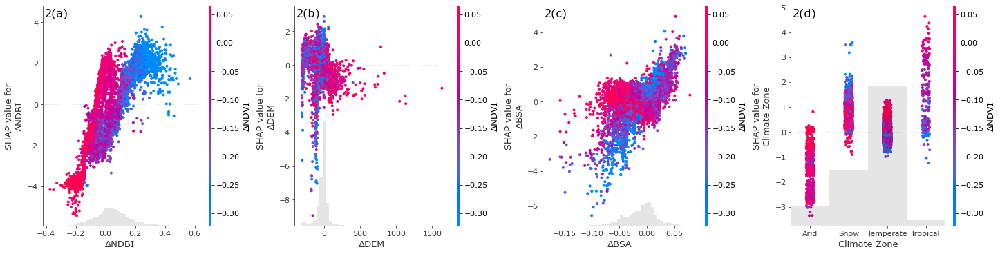

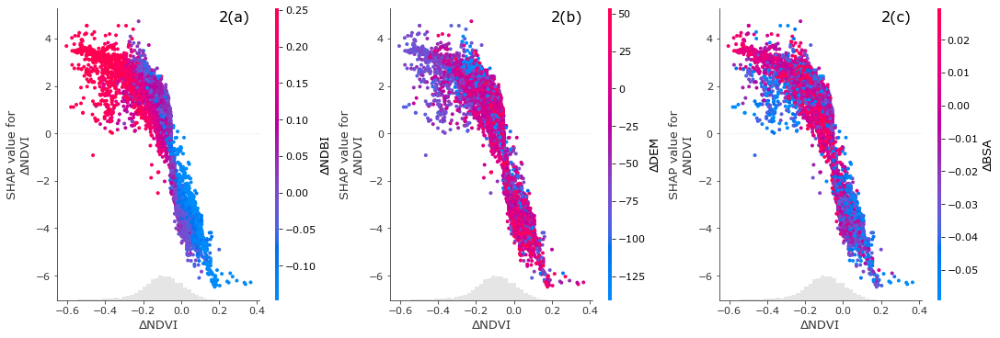

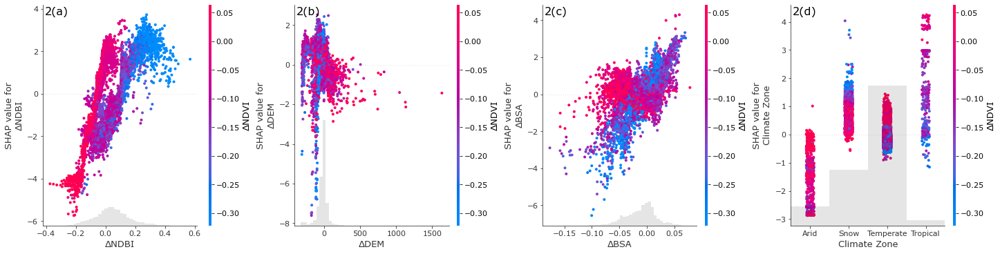

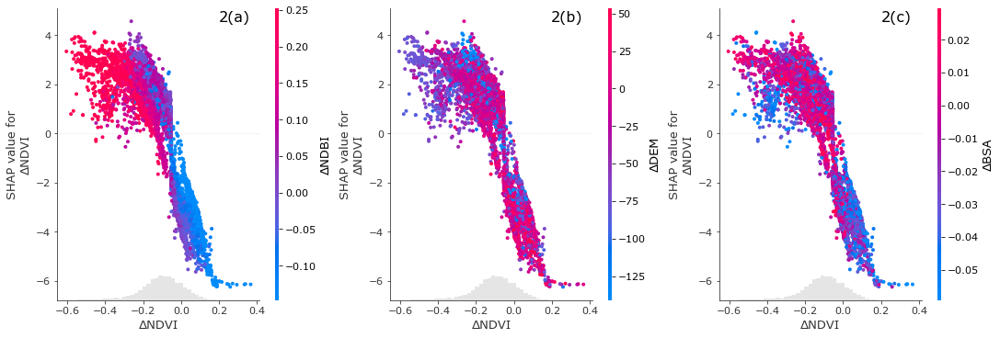

In [19]:
run_all(data_ntl, 'NTL')